In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error 


In [3]:
df = pd.read_csv('C:/Users/mon/csv/storesales/train.csv')
df.head()


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [4]:
print('shape', df.shape)

print('columns', df.columns.tolist())

print('missing values', df.isna().sum(), sep = '\n')


shape (3000888, 6)
columns ['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']
missing values
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64


In [5]:
df['date'] = pd.to_datetime(df['date'])

df = df.sort_values(
    ['store_nbr', 'family', 'date']
).reset_index(drop = True)


In [6]:
df.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1782,2013-01-02,1,AUTOMOTIVE,2.0,0
2,3564,2013-01-03,1,AUTOMOTIVE,3.0,0
3,5346,2013-01-04,1,AUTOMOTIVE,3.0,0
4,7128,2013-01-05,1,AUTOMOTIVE,5.0,0


In [7]:
df['day_of_week'] = df['date'].dt.dayofweek
df['day'] = df['date'].dt.day
df['month'] = df['date'].dt.month
df['year'] = df['date'].dt.year
df['week'] = df['date'].dt.isocalendar().week.astype(int)


In [8]:
group_cols = ['store_nbr', 'family']

for lag in [1, 7, 14, 28]:
    df[f'lag_{lag}'] = (
        df.groupby(group_cols)['sales'].shift(lag)
    )


In [9]:
df['rolling_mean_7'] = (
    df.groupby(group_cols)['sales'].transform(lambda x: x.shift(1).rolling(7).mean())
)

df['rolling_mean_28'] = (
    df.groupby(group_cols)['sales'].transform(lambda x: x.shift(1).rolling(28).mean())
)


In [10]:
df = df.dropna().reset_index(drop=True)


In [11]:
df.head()


,id,date,store_nbr,family,sales,onpromotion,day_of_week,day,month,year,week,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28
0,49896,2013-01-29,1,AUTOMOTIVE,2.0,0,1,29,1,2013,5,3.0,1.0,1.0,0.0,2.571429,2.142857
1,51678,2013-01-30,1,AUTOMOTIVE,6.0,0,2,30,1,2013,5,2.0,3.0,1.0,2.0,2.714286,2.214286
2,53460,2013-01-31,1,AUTOMOTIVE,0.0,0,3,31,1,2013,5,6.0,0.0,1.0,3.0,3.142857,2.357143
3,55242,2013-02-01,1,AUTOMOTIVE,3.0,0,4,1,2,2013,5,0.0,5.0,0.0,3.0,3.142857,2.250000
4,57024,2013-02-02,1,AUTOMOTIVE,0.0,0,5,2,2,2013,5,3.0,4.0,5.0,5.0,2.857143,2.250000


In [12]:
df[[
    "date",
    "store_nbr",
    "family",
    "sales",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]].head(20)


,date,store_nbr,family,sales,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28
0,2013-01-29,1,AUTOMOTIVE,2.0,3.0,1.0,1.0,0.0,2.571429,2.142857
1,2013-01-30,1,AUTOMOTIVE,6.0,2.0,3.0,1.0,2.0,2.714286,2.214286
2,2013-01-31,1,AUTOMOTIVE,0.0,6.0,0.0,1.0,3.0,3.142857,2.357143
3,2013-02-01,1,AUTOMOTIVE,3.0,0.0,5.0,0.0,3.0,3.142857,2.250000
4,2013-02-02,1,AUTOMOTIVE,0.0,3.0,4.0,5.0,5.0,2.857143,2.250000
5,2013-02-03,1,AUTOMOTIVE,0.0,0.0,2.0,3.0,2.0,2.285714,2.071429
6,2013-02-04,1,AUTOMOTIVE,5.0,0.0,3.0,1.0,0.0,2.000000,2.000000
7,2013-02-05,1,AUTOMOTIVE,0.0,5.0,2.0,1.0,2.0,2.285714,2.178571
8,2013-02-06,1,AUTOMOTIVE,1.0,0.0,6.0,3.0,2.0,2.000000,2.107143
9,2013-02-07,1,AUTOMOTIVE,1.0,1.0,0.0,0.0,2.0,1.285714,2.071429


In [13]:
print('shape:', df.shape)

print('missing values:', df.isna().sum(), sep = '\n')


shape: (2950992, 17)
missing values:
id                 0
date               0
store_nbr          0
family             0
sales              0
onpromotion        0
day_of_week        0
day                0
month              0
year               0
week               0
lag_1              0
lag_7              0
lag_14             0
lag_28             0
rolling_mean_7     0
rolling_mean_28    0
dtype: int64


In [14]:
max_date = df['date'].max()

validation_start = max_date - pd.Timedelta(days = 30)

train = df[df['date'] < validation_start].copy()
valid = df[df['date'] >= validation_start].copy()

print('Train:')
print(train['date'].min(), '-', train['date'].max())
print(train.shape)


print('Validation:')
print(valid['date'].min(), '-', valid['date'].max())
print(train.shape)

Train:
2013-01-29 00:00:00 - 2017-07-15 00:00:00
(2895750, 17)
Validation:
2017-07-16 00:00:00 - 2017-08-15 00:00:00
(2895750, 17)


In [15]:
features = [
    'store_nbr', 'family', 'onpromotion', 'day_of_week', 'day',
    'month', 'year', 'week', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 
    'rolling_mean_7', 'rolling_mean_28'
]

target = 'sales'

X_train = train[features]
y_train = train[target]

X_valid = valid[features]
y_valid = valid[target]


In [16]:
print(X_train.shape)
print(y_train.shape)

print(X_valid.shape)
print(y_valid.shape)


(2895750, 14)
(2895750,)
(55242, 14)
(55242,)


In [17]:
baseline_pred = valid['lag_7']


In [18]:
mae_baseline = mean_absolute_error(
    y_valid, 
    baseline_pred
)

rmse_baseline = np.sqrt(
    mean_squared_error(y_valid, baseline_pred)
)

mape_baseline = (
    np.mean(
        np.abs(
            (y_valid - baseline_pred) / np.maximum(y_valid, 1e-8)
        )
    ) * 100
)

print('baseline:')
print(f"mae : {mae_baseline:.2f}")
print(f"rmse: {rmse_baseline:.2f}")
print(f"mape: {mape_baseline:.2f}%")

baseline:
mae : 84.63
rmse: 310.16
mape: 705441552.06%


In [20]:
cat_features = ["family"]

model = CatBoostRegressor(
    iterations = 500, 
    depth = 7,
    learning_rate = 0.05,
    loss_function = "RMSE",
    random_seed = 42,
    verbose = 100
)

model.fit(
    X_train,
    y_train,
    cat_features = cat_features,
    eval_set = (X_valid, y_valid),
    early_stopping_rounds = 50
)



0:	learn: 1055.7139916	test: 1224.9279449	best: 1224.9279449 (0)	total: 640ms	remaining: 5m 19s
100:	learn: 255.5606730	test: 219.1777682	best: 219.0215850 (83)	total: 42.8s	remaining: 2m 49s
200:	learn: 240.2394995	test: 213.8014286	best: 213.8014286 (200)	total: 1m 23s	remaining: 2m 4s
300:	learn: 229.9992723	test: 210.5790385	best: 210.5122407 (298)	total: 2m 3s	remaining: 1m 21s
400:	learn: 222.9689505	test: 209.1149983	best: 209.1149983 (400)	total: 2m 43s	remaining: 40.4s
499:	learn: 217.7965634	test: 207.7927845	best: 207.7927845 (499)	total: 3m 23s	remaining: 0us

bestTest = 207.7927845
bestIteration = 499



CatBoostRegressor(depth=7, iterations=500, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=100)

In [21]:
pred = model.predict(X_valid)


In [22]:
print(pred[:10])
print(y_valid.values[:10])


[-18.36724634  16.62447042  13.85170484  10.49861259   8.28578764
   6.63768302  -1.50712132 -18.18404953  13.20600786  12.48201441]
[ 2.  2.  3.  7.  4. 10.  8.  0.  4. 10.]


In [25]:
mae = mean_absolute_error(y_valid, pred)

rmse = np.sqrt(mean_squared_error(y_valid, pred))

mape = (np.mean(np.abs((y_valid - pred) / np.maximum(y_valid, 1e-8))) * 100)


In [26]:
print('catboost')
print(f'mae: {mae:.2f}')
print(f'rmse: {rmse:.2f}')
print(f'mape: {mape:.2f}')


catboost
mae: 62.94
rmse: 207.79
mape: 4560656104.06


In [27]:
importance = pd.DataFrame({
    'feature' : features,
    'importance' : model.feature_importances_
}).sort_values('importance', ascending = False)

importance

,feature,importance
12,rolling_mean_7,21.896569
8,lag_1,18.740725
9,lag_7,17.761187
10,lag_14,13.681275
3,day_of_week,7.182130
11,lag_28,5.403817
4,day,5.160410
7,week,3.514176
2,onpromotion,2.174822
5,month,1.752244


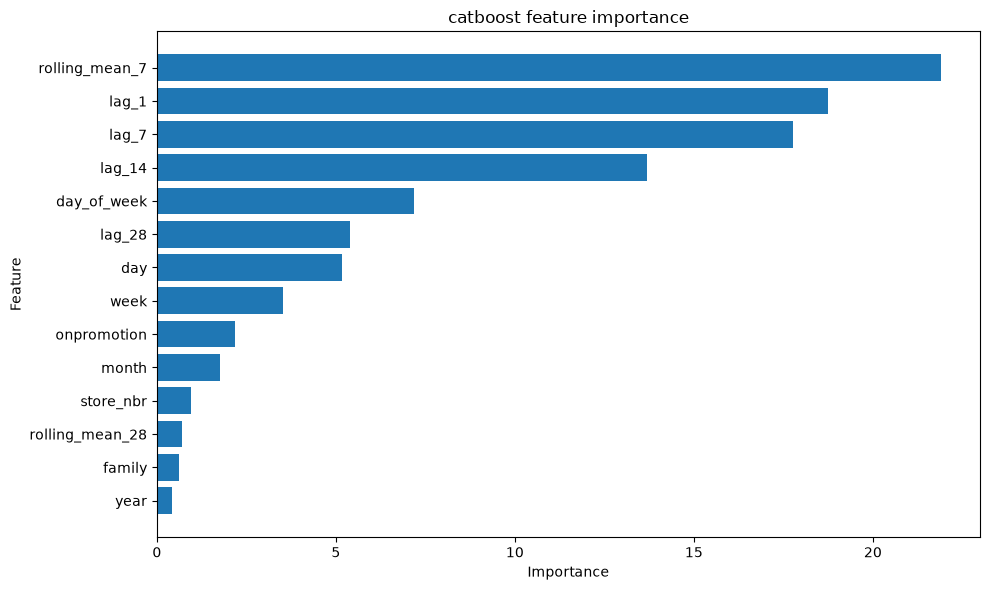

In [28]:
plt.figure(figsize = (10, 6))

plt.barh(
    importance['feature'],
    importance['importance']
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('catboost feature importance')
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


In [29]:
import lightgbm as lgb
import optuna


C:\Users\mon\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [30]:
X_train_lgb = X_train.copy()
X_valid_lgb = X_valid.copy()

X_train_lgb["family"] = X_train_lgb["family"].astype("category")
X_valid_lgb['family'] = X_valid_lgb["family"].astype('category')


In [31]:
lgb_model = lgb.LGBMRegressor(
    n_estimators = 500,
    learning_rate = 0.05,
    num_leaves = 32,
    max_depth = -1,
    random_state = 42,
    verbosity = -1
)

lgb_model.fit(
    X_train_lgb,
    y_train,
    categorical_feature = ['family'],
    eval_set = [(X_valid_lgb, y_valid)],
    callbacks = [
        lgb.early_stopping(50),
        lgb.log_evaluation(100)
    ]
)


C:\Users\mon\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[100]	valid_0's l2: 43917.9
[200]	valid_0's l2: 42796.4
[300]	valid_0's l2: 42341
Early stopping, best iteration is:
[259]	valid_0's l2: 42251


,num_leaves,32
,learning_rate,0.05
,n_estimators,500
,random_state,42
,verbosity,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


In [32]:
lgb_pred = lgb_model.predict(X_valid_lgb)


In [35]:
lgb_mae = mean_absolute_error(y_valid, lgb_pred)

lgb_rmse = np.sqrt(mean_squared_error(y_valid, lgb_pred))

print("LGBM")
print(f"mae: {lgb_mae:.2f}")
print(f'rmse: {lgb_rmse:.2f}')


LGBM
mae: 60.88
rmse: 205.55


In [45]:
def objective(trial):

    params = {
        'n_estimators' : 1000,
        
        'learning_rate' : trial.suggest_float(
            'learning_rate', 0.01, 0.1, log = True
        ),

        'num_leaves' : trial.suggest_int(
            'num_leaves', 20, 150
        ),

        'max_depth' : trial.suggest_int(
            'max_depth', 3, 12
        ),

        'min_child_samples' : trial.suggest_int(
            'min_child_samples', 10, 100
        ),

        'colsample_bytree' : trial.suggest_float(
            'colsample_bytree', 0.6, 1.0
        ),

        'reg_alpha' : trial.suggest_float(
            'reg_alpha', 1e-8, 10.0, log = True
        ),

        'reg_lambda' : trial.suggest_float(
            'reg_lambda', 1e-8, 10.0, log = True
        ),

        'random_state' : 42,

        'verbosity' : -1
    }

    model= lgb.LGBMRegressor(**params)

    model.fit(
        X_train_lgb,
        y_train,
        categorical_feature = ['family'],
        eval_set = [(X_valid_lgb, y_valid)],
        callbacks = [
            lgb.early_stopping(50, verbose = False)
        ]
    )

    pred = model.predict(X_valid_lgb)

    return mean_absolute_error(y_valid, pred)
    


    

In [46]:
study = optuna.create_study(
    direction = 'minimize'
)

study.optimize(
    objective,
    n_trials = 10
)


[I 2026-10-02 22:13:59,424] A new study created in memory with name: no-name-eeb34149-5923-474d-9f31-bee86dd6e8c2
C:\Users\mon\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
[I 2026-10-02 22:14:19,335] Trial 0 finished with value: 64.4668365232616 and parameters: {'learning_rate': 0.01023485555639804, 'num_leaves': 75, 'max_depth': 4, 'min_child_samples': 68, 'colsample_bytree': 0.8735287983292774, 'reg_alpha': 0.0018188993215677086, 'reg_lambda': 0.000528196465744668}. Best is trial 0 with value: 64.4668365232616.
C:\Users\mon\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval

In [47]:
print("Best MAE:", study.best_value)
print("Best params:")
print(study.best_params)

Best MAE: 55.970048331207146
Best params:
{'learning_rate': 0.03760863325832609, 'num_leaves': 78, 'max_depth': 10, 'min_child_samples': 47, 'colsample_bytree': 0.739943846666534, 'reg_alpha': 3.3484178736925806e-05, 'reg_lambda': 0.0005908124448839288}


In [49]:
best_params = study.best_params.copy()

best_params['n_estimators'] = 1000
best_params['random_state'] = 42
best_params['verbosity'] = -1
best_params['n_jobs'] = -1

best_lgb = lgb.LGBMRegressor(**best_params)

best_lgb.fit(
    X_train_lgb,
    y_train,
    categorical_feature = ['family'],
    eval_X = X_valid_lgb,
    eval_y = y_valid,
    callbacks = [
        lgb.early_stopping(50),
        lgb.log_evaluation(100)
    ]
)


Training until validation scores don't improve for 50 rounds
[100]	valid_0's l2: 43016.1
[200]	valid_0's l2: 40444.4
[300]	valid_0's l2: 39472.7
[400]	valid_0's l2: 39123.1
[500]	valid_0's l2: 38750.8
[600]	valid_0's l2: 38479.1
[700]	valid_0's l2: 37942
[800]	valid_0's l2: 37837.3
[900]	valid_0's l2: 37670.5
[1000]	valid_0's l2: 37589.5
Did not meet early stopping. Best iteration is:
[990]	valid_0's l2: 37586.3


,num_leaves,78
,max_depth,10
,learning_rate,0.03760863325832609
,n_estimators,1000
,min_child_samples,47
,colsample_bytree,0.739943846666534
,reg_alpha,3.3484178736925806e-05
,reg_lambda,0.0005908124448839288
,random_state,42
,n_jobs,-1
,verbosity,-1


In [50]:
best_pred = best_lgb.predict(X_valid_lgb)

best_mae = mean_absolute_error(y_valid, best_pred)

best_rmse = np.sqrt(mean_squared_error(y_valid, best_pred))

print('optimized lgbm')
print(f'mae : {best_mae:.2f}')
print(f'rmse : {best_rmse:.2f}')


optimized lgbm
mae : 55.97
rmse : 193.87
